In [8]:
import pandas as pd
import numpy as np

In [9]:
df = pd.read_csv('../data/benefit.csv')
df

,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะนำไปใช้ประโยชน์
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,0.00
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,0.00
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,0.00
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,0.00
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,0.00
...,...,...,...,...,...,...
2650,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,0.00
2651,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,0.00
2652,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางศรีเมือง,0.22
2653,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,อบต.บางไผ่,0.00


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ปี                  2655 non-null   int64  
 1   เดือน               2655 non-null   str    
 2   จังหวัด             2655 non-null   str    
 3   อำเภอ               2655 non-null   str    
 4   อปท                 2655 non-null   str    
 5   ขยะนำไปใช้ประโยชน์  2655 non-null   float64
dtypes: float64(1), int64(1), str(4)
memory usage: 124.6 KB


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
for col in df.columns[1:5]:
    df[col] = df[col].astype('category')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   ปี                  2655 non-null   int64   
 1   เดือน               2655 non-null   category
 2   จังหวัด             2655 non-null   category
 3   อำเภอ               2655 non-null   category
 4   อปท                 2655 non-null   category
 5   ขยะนำไปใช้ประโยชน์  2655 non-null   float64 
dtypes: category(4), float64(1), int64(1)
memory usage: 52.5 KB


In [15]:
#Save clean data
df.to_csv("../clean_data/clean_benefit.csv", index=False)

## การแสดงผลข้อมูล: ปริมาณขยะมูลฝอยที่นำไปใช้ประโยชน์

แสดงผลใน 3 มุมมอง:
1. **รายปี** — แนวโน้มภาพรวมตลอด 5 ปี
2. **รายอำเภอ** — เปรียบเทียบแต่ละพื้นที่
3. **รายเดือน** — รูปแบบตามฤดูกาล

ใช้ฟอนต์: TH Sarabun New


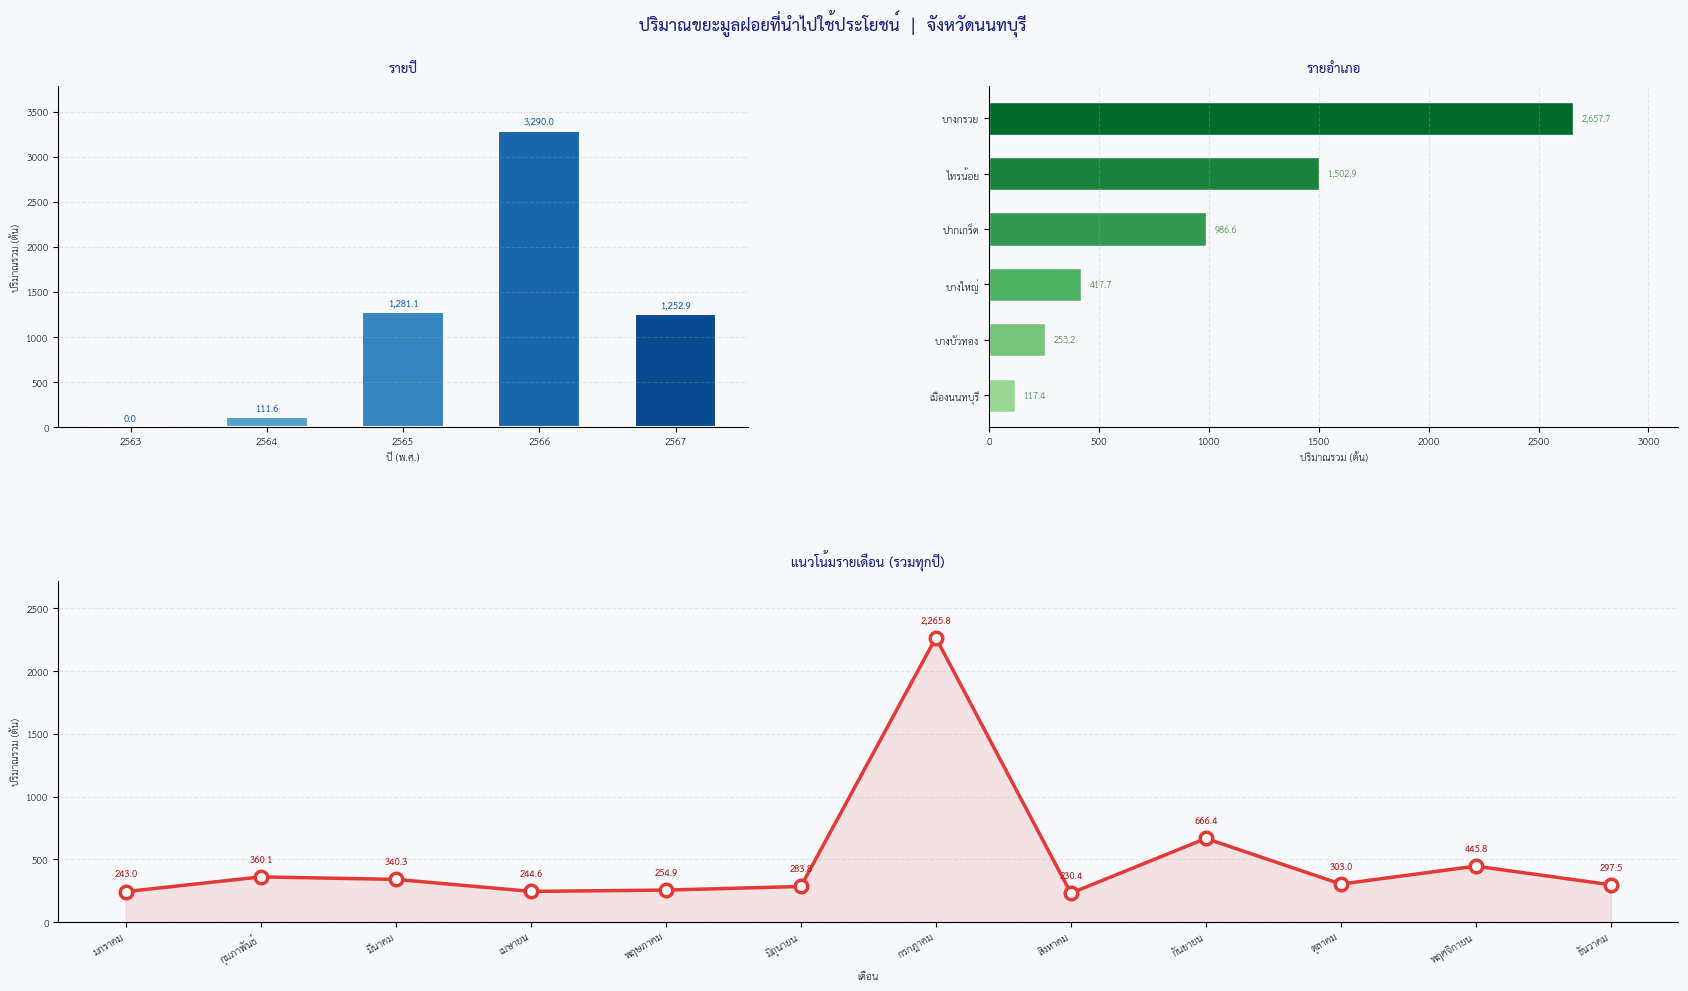

บันทึกภาพสำเร็จ: benefit_visualization.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ---- Thai Font Setup ----
# ลองใช้ฟอนต์ภาษาไทยตามลำดับ
thai_font_candidates = ['TH Sarabun New', 'Tahoma', 'Leelawadee UI', 'Arial Unicode MS', 'DejaVu Sans']
available_fonts = {f.name for f in fm.fontManager.ttflist}
chosen_font = next((f for f in thai_font_candidates if f in available_fonts), 'DejaVu Sans')
plt.rcParams['font.family'] = chosen_font
plt.rcParams['axes.unicode_minus'] = False
print(f"ใช้ฟอนต์: {chosen_font}")

# ---- Load & Prepare Data ----
df_viz = pd.read_csv('../clean_data/clean_benefit.csv')

yearly   = df_viz.groupby('ปี')['ขยะนำไปใช้ประโยชน์'].sum().reset_index()
district = (df_viz.groupby('อำเภอ')['ขยะนำไปใช้ประโยชน์']
            .sum().reset_index()
            .sort_values('ขยะนำไปใช้ประโยชน์', ascending=True))

month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
monthly = (df_viz.groupby('เดือน')['ขยะนำไปใช้ประโยชน์']
           .sum().reindex(month_order).fillna(0))

# ---- Figure Layout ----
fig = plt.figure(figsize=(18, 11))
fig.patch.set_facecolor('#F7F9FC')
gs = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.35,
                      left=0.07, right=0.97, top=0.88, bottom=0.12)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

fig.suptitle('ปริมาณขยะมูลฝอยที่นำไปใช้ประโยชน์  |  จังหวัดนนทบุรี',
             fontsize=18, fontweight='bold', color='#1A237E', y=0.95)

def style_ax(ax):
    ax.set_facecolor('#F7F9FC')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    ax.tick_params(labelsize=11)

# ──────────────────────────────────────────────
# Plot 1 : รายปี (Bar chart)
# ──────────────────────────────────────────────
style_ax(ax1)
ax1.grid(axis='x', alpha=0)  # ปิด grid แนวนอน
colors_yr = plt.cm.Blues(np.linspace(0.45, 0.90, len(yearly)))
bars1 = ax1.bar(yearly['ปี'].astype(str), yearly['ขยะนำไปใช้ประโยชน์'],
                color=colors_yr, edgecolor='white', linewidth=1.5, width=0.6)
ax1.set_title('รายปี', fontsize=14, fontweight='bold', pad=10, color='#1A237E')
ax1.set_xlabel('ปี (พ.ศ.)', fontsize=11)
ax1.set_ylabel('ปริมาณรวม (ตัน)', fontsize=11)
y_max = yearly['ขยะนำไปใช้ประโยชน์'].max()
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., h + y_max*0.015,
             f'{h:,.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1565C0')
ax1.set_ylim(0, y_max * 1.15)


# ──────────────────────────────────────────────
# Plot 3 : รายเดือน (Line + fill)
# ──────────────────────────────────────────────
style_ax(ax3)
ax3.grid(axis='x', alpha=0)
x = np.arange(len(month_order))
ax3.fill_between(x, monthly.values, alpha=0.12, color='#E53935')
ax3.plot(x, monthly.values, 'o-', color='#E53935',
         linewidth=2.5, markersize=9, zorder=3, markerfacecolor='white',
         markeredgewidth=2.5)
# Label each point
for xi, yi in zip(x, monthly.values):
    ax3.annotate(f'{yi:,.1f}', (xi, yi),
                 textcoords='offset points', xytext=(0, 11),
                 ha='center', fontsize=10, fontweight='bold', color='#B71C1C')
ax3.set_title('แนวโน้มรายเดือน (รวมทุกปี)', fontsize=14, fontweight='bold', pad=10, color='#1A237E')
ax3.set_xlabel('เดือน', fontsize=11)
ax3.set_ylabel('ปริมาณรวม (ตัน)', fontsize=11)
ax3.set_xticks(x)
ax3.set_xticklabels(month_order, rotation=30, ha='right', fontsize=11)
ax3.set_xlim(-0.5, len(month_order) - 0.5)
ax3.set_ylim(0, monthly.values.max() * 1.20)

plt.savefig('benefit_visualization.png', dpi=150, bbox_inches='tight', facecolor='#F7F9FC')
plt.show()
print("บันทึกภาพสำเร็จ: benefit_visualization.png")